# 16 · Sequence Models — RNNs, LSTMs, Attention & Transformers

Text, speech, music, DNA, user click streams, sensor readings: much of the world's data is a **sequence**, where order carries meaning. "The dog bit the man" ≠ "the man bit the dog". This notebook follows the history of neural sequence models, building each one from scratch:

**What you'll learn**
1. Why order matters — where bag-of-words models break
2. **Recurrent neural networks (RNNs):** a loop with memory — forward pass and **backpropagation through time** in NumPy
3. **Vanishing and exploding gradients** — why plain RNNs forget
4. **LSTMs and GRUs:** gates and an additive memory lane — and a memory test RNNs fail
5. **Attention:** letting every position look at every other — 🐍 pure Python → 🔢 NumPy → 📦 PyTorch; scaling, masking, multi-head
6. **Positional encodings** — attention alone ignores order
7. A **transformer** built from its parts, trained on a sentiment task, with its attention maps
8. The cost of attention and why transformers replaced RNNs

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, time, random
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0)
from text_data import make_reviews

## 1. Why order matters

Our review dataset (generated by `text_data.py`) has three kinds of sentence:

| Kind | Example | Label |
|---|---|---|
| plain | "the battery is great" | positive |
| negated | "the battery is **not** great" | negative |
| contrast | "the case is bad **but** the screen is great" | positive (the part after "but" decides; it may itself be negated) |

A **bag-of-words** model (notebook 04's Naive Bayes, or logistic regression on word counts) sees only *which* words appear, not their order. Let's see where that breaks.

In [2]:
texts, labels = make_reviews(5000, seed=0)
labels = np.array(labels)
kind = np.array(["contrast" if " but " in t else "negated" if any(w in t.split() for w in ["not", "never", "hardly"]) else "plain" for t in texts])
for k in ["plain", "negated", "contrast"]:
    print(f"{k:9s} e.g. {texts[np.where(kind == k)[0][0]]!r} → {labels[np.where(kind == k)[0][0]]}")

idx_tr, idx_te = np.arange(4000), np.arange(4000, 5000)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
vec = CountVectorizer().fit([texts[i] for i in idx_tr])
bow = LogisticRegression(max_iter=2000).fit(vec.transform([texts[i] for i in idx_tr]), labels[idx_tr])
pred_bow = bow.predict(vec.transform([texts[i] for i in idx_te]))

def by_kind(pred):
    return {k: round(float(np.mean(pred[kind[idx_te] == k] == labels[idx_te][kind[idx_te] == k])), 3) for k in ["plain", "negated", "contrast"]} | {"overall": round(float(np.mean(pred == labels[idx_te])), 3)}
results = {"bag of words + logistic regression": by_kind(pred_bow)}

# Patch attempt: add word PAIRS (bigrams) like "not great" as features
vec2 = CountVectorizer(ngram_range=(1, 2)).fit([texts[i] for i in idx_tr])
bow2 = LogisticRegression(max_iter=2000).fit(vec2.transform([texts[i] for i in idx_tr]), labels[idx_tr])
results["bag of words + bigrams"] = by_kind(bow2.predict(vec2.transform([texts[i] for i in idx_te])))
import pandas as pd
pd.DataFrame(results).T

plain     e.g. 'for the price the mouse is great' → 1
negated   e.g. 'in my opinion the battery is hardly useless' → 1
contrast  e.g. 'so far the app is amazing but the mouse is reliable' → 1


,plain,negated,contrast,overall
bag of words + logistic regression,0.81,0.232,0.499,0.522
bag of words + bigrams,1.00,1.000,1.000,1.000


**Plain bag-of-words** gets plain sentences mostly right but is *worse than chance* on negations: it sees "great" and says positive. On contrast sentences it's at chance, because it can't tell which clause came after "but".

**Adding bigrams** (word pairs as features) fixes everything here, and cleverly so. "not great" becomes its own feature, and the model learns that "great but" should *cancel* "is great". That works because every decisive cue in this toy dataset sits within two neighbouring words.

Real language isn't that kind. Negation can reach far ("I don't think the battery, despite the reviews, is great"). Meaning depends on things said sentences earlier, and phrasings combine in endless ways. Covering that with n-grams makes the feature space explode, and n-grams never generalise to word combinations they haven't seen. Sequence models learn order-dependent meaning in **one** model, from embeddings that generalise across similar words. Below, both sequence models also solve this task, without any hand-made features.

## 2. Recurrent neural networks

An RNN reads a sequence one step at a time and keeps a **hidden state** $\mathbf{h}_t$ — a running summary of everything so far:
$$ \mathbf{h}_t = \tanh(W_x\mathbf{x}_t + W_h\mathbf{h}_{t-1} + \mathbf{b}), \qquad \hat{\mathbf{y}}_t = W_y\mathbf{h}_t + \mathbf{b}_y $$
The **same weights** are used at every step (weight sharing across time — like a CNN shares across space). "Unrolled", it's a very deep network with one layer per time step:
```
x₁ → [RNN] → h₁ → [RNN] → h₂ → [RNN] → h₃ → … → h_T → prediction
       ↑            ↑            ↑
     same weights at every step
```

In [3]:
# 🐍 Pure Python: one RNN step and a short sequence, hidden size 2, input size 1
def rnn_step_python(x, h, Wx, Wh, b):
    return [math.tanh(sum(Wx[i][j] * x[j] for j in range(len(x))) + sum(Wh[i][j] * h[j] for j in range(len(h))) + b[i]) for i in range(len(h))]

Wx, Wh, b = [[0.5], [-0.3]], [[0.8, -0.1], [0.2, 0.9]], [0.0, 0.1]
h = [0.0, 0.0]
for t, x in enumerate([1.0, 0.0, 0.0, -1.0]):
    h = rnn_step_python([x], h, Wx, Wh, b)
    print(f"t={t}: input {x:+.0f} → hidden state {np.round(h, 3)}")
print("The input at t=0 still echoes in the state later — that's memory.")

t=0: input +1 → hidden state [ 0.462 -0.197]
t=1: input +0 → hidden state [0.371 0.015]
t=2: input +0 → hidden state [0.287 0.185]
t=3: input -1 → hidden state [-0.281  0.554]
The input at t=0 still echoes in the state later — that's memory.


### Training: backpropagation through time (BPTT)
Unroll the loop, run ordinary backprop backwards through every time step, and **add up** each weight's gradient over all the steps (the weights are shared). Below, a NumPy RNN learns to predict the next value of noisy sine waves. Every gradient line is the chain rule from notebook 07, applied one step at a time.

gradient check on Wh[3,5]: BPTT 7.572156e-03 vs numerical 7.572156e-03


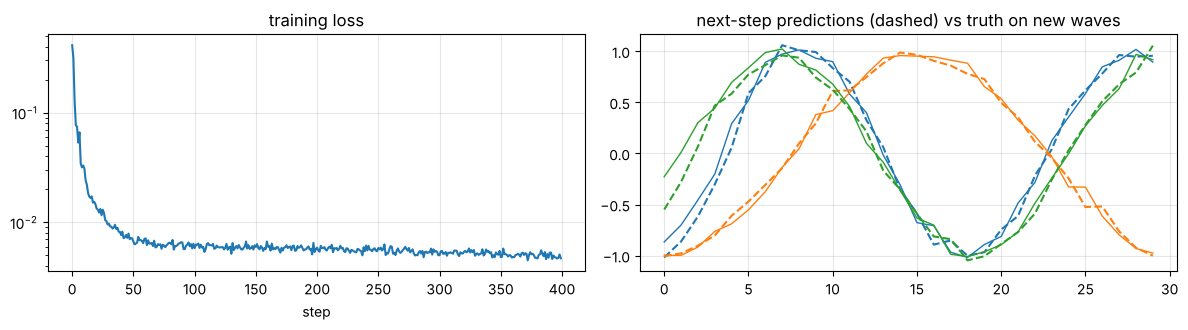

In [4]:
# 🔢 NumPy RNN with hand-written BPTT
class RNNNumpy:
    def __init__(self, n_in, n_hidden, n_out, seed=0):
        r = np.random.default_rng(seed); s = 1 / np.sqrt(n_hidden)
        self.p = {"Wx": r.normal(0, s, (n_in, n_hidden)), "Wh": r.normal(0, s, (n_hidden, n_hidden)), "b": np.zeros(n_hidden),
                  "Wy": r.normal(0, s, (n_hidden, n_out)), "by": np.zeros(n_out)}
    def forward(self, X):                       # X: (T, B, n_in)
        T, B, _ = X.shape; H = self.p["Wh"].shape[0]
        self.X, self.hs = X, [np.zeros((B, H))]
        for t in range(T):
            self.hs.append(np.tanh(X[t] @ self.p["Wx"] + self.hs[-1] @ self.p["Wh"] + self.p["b"]))
        return np.stack([h @ self.p["Wy"] + self.p["by"] for h in self.hs[1:]])     # (T, B, n_out)
    def backward(self, dY):                     # dY = dLoss/dPredictions, (T, B, n_out)
        g = {k: np.zeros_like(v) for k, v in self.p.items()}
        dh_next = np.zeros_like(self.hs[0])
        for t in reversed(range(len(dY))):
            h, h_prev = self.hs[t + 1], self.hs[t]
            g["Wy"] += h.T @ dY[t]; g["by"] += dY[t].sum(0)
            dh = dY[t] @ self.p["Wy"].T + dh_next           # from this step's output + from the future
            dz = dh * (1 - h ** 2)                          # back through tanh
            g["Wx"] += self.X[t].T @ dz; g["Wh"] += h_prev.T @ dz; g["b"] += dz.sum(0)
            dh_next = dz @ self.p["Wh"].T                   # pass the gradient to the previous time step
        return g

def make_sines(n, T=30, seed=0):
    r = np.random.default_rng(seed); t = np.arange(T + 1)
    freq, phase = r.uniform(0.15, 0.35, n), r.uniform(0, 2 * np.pi, n)
    s = np.sin(freq[:, None] * t + phase[:, None]) + r.normal(0, 0.05, (n, T + 1))
    return s[:, :-1].T[..., None], s[:, 1:].T[..., None]          # inputs and next-step targets, (T, n, 1)

Xs, Ys = make_sines(512)
rnn = RNNNumpy(1, 32, 1)

# Gradient check on a small batch before training (notebook 07's trick)
Xc, Yc = Xs[:, :8], Ys[:, :8]
loss_fn = lambda: 0.5 * np.mean((rnn.forward(Xc) - Yc) ** 2)
g = rnn.backward((rnn.forward(Xc) - Yc) / Yc.size)
i, j = 3, 5; old = rnn.p["Wh"][i, j]
rnn.p["Wh"][i, j] = old + 1e-5; lp = loss_fn(); rnn.p["Wh"][i, j] = old - 1e-5; lm = loss_fn(); rnn.p["Wh"][i, j] = old
print(f"gradient check on Wh[3,5]: BPTT {g['Wh'][i, j]:.6e} vs numerical {(lp - lm) / 2e-5:.6e}")

# Train with Adam + gradient clipping
m_, v_ = {k: 0 for k in rnn.p}, {k: 0 for k in rnn.p}; losses = []
for step in range(1, 401):
    idx = rng.integers(0, 512, 64)
    pred = rnn.forward(Xs[:, idx]); err = pred - Ys[:, idx]
    losses.append(0.5 * np.mean(err ** 2))
    grads = rnn.backward(err / err.size)
    norm = np.sqrt(sum((gv ** 2).sum() for gv in grads.values()))
    for k in rnn.p:
        gk = grads[k] * min(1.0, 1.0 / (norm + 1e-12))                 # clip the global gradient norm at 1
        m_[k] = 0.9 * m_[k] + 0.1 * gk; v_[k] = 0.999 * v_[k] + 0.001 * gk ** 2
        rnn.p[k] -= 0.01 * (m_[k] / (1 - 0.9 ** step)) / (np.sqrt(v_[k] / (1 - 0.999 ** step)) + 1e-8)

Xv, Yv = make_sines(3, seed=9); pv = rnn.forward(Xv)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(losses); ax[0].set_yscale("log"); ax[0].set_title("training loss"); ax[0].set_xlabel("step")
for k in range(3):
    ax[1].plot(Yv[:, k, 0], c=f"C{k}", lw=1); ax[1].plot(pv[:, k, 0], "--", c=f"C{k}")
ax[1].set_title("next-step predictions (dashed) vs truth on new waves"); plt.tight_layout(); plt.show()

Early time steps are poor (the network hasn't seen enough of the wave to know its frequency yet), then predictions lock on. The hidden state has learned to track phase and frequency.

## 3. Vanishing and exploding gradients

The gradient flowing from step $T$ back to step $0$ is a **product of T Jacobians**:
$$ \frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_0} = \prod_{t=1}^{T} \text{diag}(1 - \mathbf{h}_t^2)\, W_h^\top $$
Multiply many matrices together and the result **shrinks to zero** if their "size" (largest singular value) is below 1, or **explodes** if above 1. So a plain RNN gets almost no learning signal about long-range dependencies — it effectively has short-term memory only. (Exploding gradients are tamed by **clipping**, as above; vanishing ones need a different architecture.)

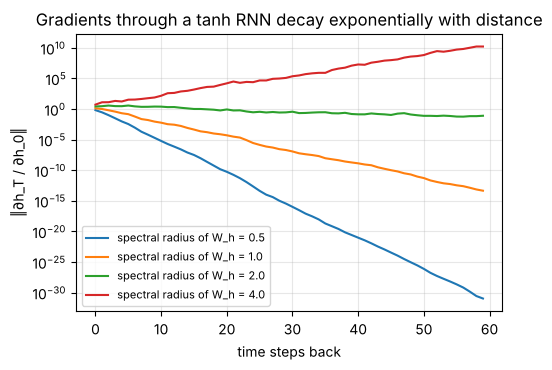

In [5]:
def gradient_through_time(scale, T=60, H=32, seed=0):
    r = np.random.default_rng(seed)
    Wh = r.normal(0, 1, (H, H)); Wh *= scale / np.max(np.abs(np.linalg.eigvals(Wh)))    # set the spectral radius
    h, J, norms = np.zeros(H), np.eye(H), []
    for t in range(T):
        h = np.tanh(Wh @ h + r.normal(0, 1, H))
        J = (np.diag(1 - h ** 2) @ Wh) @ J                # chain rule: accumulate ∂h_t/∂h_0
        norms.append(np.linalg.norm(J, 2))
    return norms

for scale in [0.5, 1.0, 2.0, 4.0]:
    plt.semilogy(gradient_through_time(scale), label=f"spectral radius of W_h = {scale}")
plt.xlabel("time steps back"); plt.ylabel("‖∂h_T / ∂h_0‖"); plt.legend(fontsize=8)
plt.title("Gradients through a tanh RNN decay exponentially with distance"); plt.show()

Even with large weights, the tanh saturates (its derivative $1 - h^2 \to 0$), so gradients vanish after a few dozen steps in practice.

## 4. LSTMs and GRUs

The **Long Short-Term Memory** cell (1997) adds a separate **cell state** $\mathbf{c}_t$ — a memory lane that information can travel along with only *additive* changes — controlled by three **gates** (sigmoid outputs between 0 and 1, i.e. soft switches):
$$
\begin{aligned}
\mathbf{f}_t &= \sigma(W_f[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_f) && \text{forget gate: how much old memory to keep} \\
\mathbf{i}_t &= \sigma(W_i[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_i) && \text{input gate: how much new information to write} \\
\tilde{\mathbf{c}}_t &= \tanh(W_c[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c) && \text{candidate new information} \\
\mathbf{c}_t &= \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t && \text{update the memory (additive!)} \\
\mathbf{o}_t &= \sigma(W_o[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_o), \quad \mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t) && \text{output gate: what to reveal}
\end{aligned}
$$
The key line is $\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \dots$: the gradient along the cell state is multiplied only by the forget gate. When $\mathbf{f} \approx 1$, gradients pass through hundreds of steps almost unchanged — the same idea as ResNet's skip connections (notebook 15).

The **GRU** (2014) is a simpler variant with two gates (update, reset) and no separate cell state; it usually performs similarly.

In [6]:
# 📦 An LSTM cell written from its equations, checked against PyTorch's nn.LSTM
class LSTMCellScratch(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.W = nn.Linear(n_in + n_hidden, 4 * n_hidden)   # all four gates in one matrix multiply
        self.H = n_hidden
    def forward(self, x, state):
        h, c = state
        z = self.W(torch.cat([x, h], dim=-1))
        i, f, g, o = z.split(self.H, dim=-1)                 # PyTorch's gate order: input, forget, cell, output
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

ref = nn.LSTM(8, 16, batch_first=True); cell = LSTMCellScratch(8, 16)
with torch.no_grad():                                         # copy PyTorch's weights into our cell
    cell.W.weight.copy_(torch.cat([ref.weight_ih_l0, ref.weight_hh_l0], dim=1)); cell.W.bias.copy_(ref.bias_ih_l0 + ref.bias_hh_l0)
x = torch.randn(4, 10, 8); h = c = torch.zeros(4, 16)
for t in range(10): h, c = cell(x[:, t], (h, c))
print("our LSTM cell == nn.LSTM:", torch.allclose(h, ref(x)[0][:, -1], atol=1e-6))

our LSTM cell == nn.LSTM: True


### A memory test
Each input is a sequence of random digits. **The label depends only on the first digit** (is it > 5?); everything after is noise. To succeed, the model must carry one piece of information across the whole sequence.

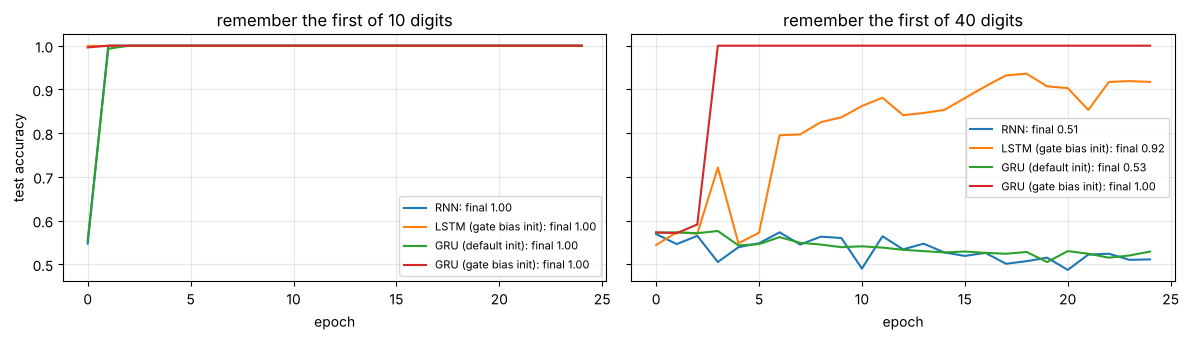

In [7]:
def memory_task(n, T, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.randint(1, 10, (n, T), generator=g)
    return x, (x[:, 0] > 5).long()

class SeqClassifier(nn.Module):
    def __init__(self, kind, vocab=10, emb=16, hidden=32, remember_init=True):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 2)
        if kind in ("LSTM", "GRU") and remember_init:
            # Start the gates in "keep the memory" mode: bias +1 on the LSTM forget gate / the GRU update gate.
            # In PyTorch both happen to be the SECOND block of the stacked gate biases.
            for name, p in self.rnn.named_parameters():
                if "bias" in name: p.data[hidden:2 * hidden] = 1.0
    def forward(self, x):
        out, _ = self.rnn(self.emb(x))
        return self.out(out[:, -1])                           # classify from the final hidden state

def fit(model, Xtr, ytr, Xte, yte, epochs=25, lr=5e-3, batch=64):
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(ytr))
        for i in range(0, len(ytr), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        model.eval()
        with torch.no_grad(): hist.append((model(Xte).argmax(1) == yte).float().mean().item())
    return hist

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, T in zip(axes, [10, 40]):
    Xtr_m, ytr_m = memory_task(4000, T, 1); Xte_m, yte_m = memory_task(1000, T, 2)
    for kind_, init in [("RNN", False), ("LSTM", True), ("GRU", False), ("GRU", True)]:
        torch.manual_seed(0)
        h_ = fit(SeqClassifier(kind_, remember_init=init), Xtr_m, ytr_m, Xte_m, yte_m)
        lbl = kind_ + (" (gate bias init)" if init else " (default init)" if kind_ != "RNN" else "")
        ax.plot(h_, label=f"{lbl}: final {h_[-1]:.2f}")
    ax.set_title(f"remember the first of {T} digits"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
axes[0].set_ylabel("test accuracy"); plt.tight_layout(); plt.show()

With 10 steps everything works. With 40 steps the plain RNN is stuck at a coin flip. The gated models succeed **when their gates start out in "remember" mode**. With default initialisation the GRU also fails: gates *can* keep memory, but only if training finds that setting, and the faint gradients from 40 steps back give it little to go on. Initialising the forget/update-gate bias to +1 is a standard, cheap trick, and a reminder that **architecture and initialisation work together**.

## 5. Attention

RNNs have two deeper problems:
1. **A bottleneck.** In translation (encoder–decoder RNNs), the whole source sentence had to be squeezed into one fixed-size vector.
2. **Sequential computation.** Step t needs step t−1, so you can't parallelise across the sequence on a GPU.

**Attention** (2014, then "Attention Is All You Need", 2017) lets each position **directly look at every other position** and pull in what it needs.

Think of a soft dictionary lookup. Each position emits:
- a **query** $\mathbf{q}$: "what am I looking for?"
- a **key** $\mathbf{k}$: "what do I contain?"
- a **value** $\mathbf{v}$: "what will I hand over if chosen?"

Each query is compared with every key (dot product = similarity, notebook 14). A softmax turns the scores into weights that sum to 1, and the output is the weighted average of the values:
$$ \text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V $$
In **self-attention**, Q, K and V are all computed from the same sequence: $Q = XW_Q$, $K = XW_K$, $V = XW_V$.

In [8]:
# 🐍 Pure Python scaled dot-product attention
def softmax_python(xs):
    m = max(xs); e = [math.exp(x - m) for x in xs]; s = sum(e)
    return [v / s for v in e]

def attention_python(Q, K, V):
    d = len(K[0]); out, all_w = [], []
    for q in Q:
        scores = [sum(qi * ki for qi, ki in zip(q, k)) / math.sqrt(d) for k in K]   # compare query with every key
        w = softmax_python(scores); all_w.append(w)
        out.append([sum(w[j] * V[j][c] for j in range(len(V))) for c in range(len(V[0]))])   # weighted average of values
    return out, all_w

# 🔢 NumPy — the formula, line for line
def attention_numpy(Q, K, V, mask=None):
    scores = Q @ K.T / np.sqrt(K.shape[-1])
    if mask is not None:
        scores = np.where(mask, scores, -1e9)                # blocked positions get ~zero weight
    W = np.exp(scores - scores.max(-1, keepdims=True)); W /= W.sum(-1, keepdims=True)
    return W @ V, W

Q, K, V = rng.normal(size=(4, 8)), rng.normal(size=(4, 8)), rng.normal(size=(4, 8))
out_py, _ = attention_python(Q.tolist(), K.tolist(), V.tolist())
out_np, W = attention_numpy(Q, K, V)
out_t = F.scaled_dot_product_attention(torch.tensor(Q)[None], torch.tensor(K)[None], torch.tensor(V)[None])[0].numpy()   # 📦 PyTorch
print("pure Python == NumPy == PyTorch:", np.allclose(out_py, out_np), np.allclose(out_np, out_t))
print("attention weights (each row sums to 1):\n", W.round(3))

pure Python == NumPy == PyTorch: True True
attention weights (each row sums to 1):
 [[0.084 0.016 0.406 0.494]
 [0.203 0.258 0.197 0.342]
 [0.071 0.885 0.011 0.033]
 [0.176 0.725 0.047 0.053]]


### Why divide by √d?
With random vectors of dimension d, a dot product has variance ≈ d. Large scores push the softmax into near one-hot outputs whose gradients are almost zero. Dividing by √d keeps the scores' scale steady whatever the dimension.

In [9]:
for d in [4, 64, 512]:
    q, k = rng.normal(size=(1000, d)), rng.normal(size=(1000, 10, d))
    raw = np.einsum("nd,ntd->nt", q, k)
    for name, sc in [("unscaled", raw), ("÷√d", raw / np.sqrt(d))]:
        w = np.exp(sc - sc.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)
        print(f"d={d:3d} {name:9s} score std {sc.std():6.2f} | average largest attention weight {w.max(1).mean():.2f}")

d=  4 unscaled  score std   1.98 | average largest attention weight 0.49
d=  4 ÷√d       score std   0.99 | average largest attention weight 0.30
d= 64 unscaled  score std   8.02 | average largest attention weight 0.86
d= 64 ÷√d       score std   1.00 | average largest attention weight 0.32
d=512 unscaled  score std  22.56 | average largest attention weight 0.95
d=512 ÷√d       score std   1.00 | average largest attention weight 0.32


### Masking
- **Padding mask:** ignore padding tokens added to make sequences the same length.
- **Causal mask:** when generating text, position t must not see positions after t (that would be cheating). Mask the upper triangle. This is what makes a transformer a **decoder** / language model (notebook 17).

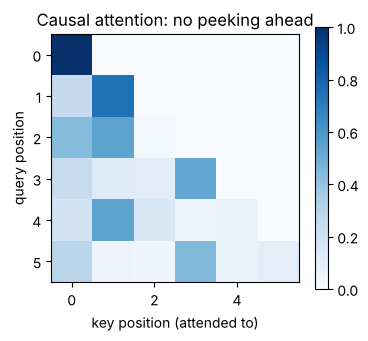

In [10]:
T = 6
causal = np.tril(np.ones((T, T), bool))
_, Wc = attention_numpy(rng.normal(size=(T, 8)), rng.normal(size=(T, 8)), rng.normal(size=(T, 8)), mask=causal)
plt.figure(figsize=(4, 3.4)); plt.imshow(Wc, cmap="Blues"); plt.colorbar()
plt.xlabel("key position (attended to)"); plt.ylabel("query position"); plt.title("Causal attention: no peeking ahead"); plt.grid(False); plt.show()

### Multi-head attention
One attention pattern can only focus on one kind of relationship at a time. **Multi-head** attention runs h smaller attentions in parallel — each with its own $W_Q, W_K, W_V$ projecting to dimension d/h — then concatenates the results and mixes them with an output matrix $W_O$. One head can track "which noun does this adjective describe", another "is there a negation nearby".

In [11]:
# 🔢 Multi-head self-attention in NumPy, checked against nn.MultiheadAttention with the same weights
def multihead_numpy(X, Wq, Wk, Wv, Wo, bq, bk, bv, bo, n_heads):
    T, d = X.shape; dh = d // n_heads
    Q, K, V = X @ Wq.T + bq, X @ Wk.T + bk, X @ Wv.T + bv
    heads = []
    for h_ in range(n_heads):                                   # each head works on its own slice of dimensions
        s = slice(h_ * dh, (h_ + 1) * dh)
        heads.append(attention_numpy(Q[:, s], K[:, s], V[:, s])[0])
    return np.concatenate(heads, axis=1) @ Wo.T + bo

d_model, n_heads = 16, 4
mha = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
Wq, Wk, Wv = [w.detach().numpy() for w in mha.in_proj_weight.chunk(3)]
bq, bk, bv = [b_.detach().numpy() for b_ in mha.in_proj_bias.chunk(3)]
X = rng.normal(size=(7, d_model)).astype(np.float32)
ours = multihead_numpy(X, Wq, Wk, Wv, mha.out_proj.weight.detach().numpy(), bq, bk, bv, mha.out_proj.bias.detach().numpy(), n_heads)
theirs = mha(torch.tensor(X)[None], torch.tensor(X)[None], torch.tensor(X)[None])[0][0].detach().numpy()
print("our multi-head attention == nn.MultiheadAttention:", np.allclose(ours, theirs, atol=1e-5))

our multi-head attention == nn.MultiheadAttention: True


## 6. Positional encoding — attention can't see order on its own

Self-attention treats its input as a **set**: shuffle the tokens and the outputs get shuffled the same way, with identical values. "Dog bites man" and "man bites dog" would look the same. Fix: **add position information** to each token's vector.

- **Sinusoidal** (original transformer): $PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d})$, $PE_{(pos, 2i+1)} = \cos(\cdot)$ — a unique "clock" pattern of many frequencies per position.
- **Learned** position embeddings (BERT, GPT-2).
- **Relative / rotary (RoPE)** — used in most modern LLMs; encodes *distances* between positions inside the attention scores.

self-attention of shuffled input == shuffled output (order is invisible): True


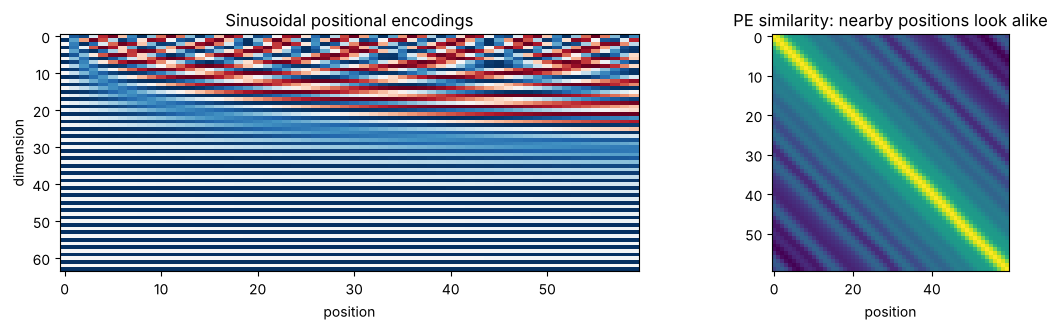

In [12]:
X = rng.normal(size=(5, 8)); perm = np.array([3, 0, 4, 1, 2])
A, _ = attention_numpy(X, X, X); Ap, _ = attention_numpy(X[perm], X[perm], X[perm])
print("self-attention of shuffled input == shuffled output (order is invisible):", np.allclose(A[perm], Ap))

def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]; i = np.arange(0, d, 2)[None]
    pe = np.zeros((n_pos, d)); pe[:, 0::2] = np.sin(pos / 10000 ** (i / d)); pe[:, 1::2] = np.cos(pos / 10000 ** (i / d))
    return pe
pe = sinusoidal_pe(60, 64)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].imshow(pe.T, aspect="auto", cmap="RdBu"); ax[0].set_xlabel("position"); ax[0].set_ylabel("dimension"); ax[0].set_title("Sinusoidal positional encodings"); ax[0].grid(False)
ax[1].imshow(pe @ pe.T, cmap="viridis"); ax[1].set_title("PE similarity: nearby positions look alike"); ax[1].set_xlabel("position"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 7. The transformer, built from its parts

A **transformer block** = multi-head self-attention + a small feed-forward network (applied to each position separately), each wrapped in a **residual connection** and **layer normalisation**:
```
x → LayerNorm → Multi-head attention → (+ x) → LayerNorm → Feed-forward (Linear → GELU → Linear) → (+) → out
```
(This "pre-norm" order is what modern models use; it trains more stably.) Stack N blocks. For classification, pool the outputs (or use a special [CLS] token) and add a linear head. **Encoder** models (BERT) see the whole sequence; **decoder** models (GPT) use the causal mask.

In [13]:
class TransformerBlock(nn.Module):
    def __init__(self, d, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Linear(d_ff, d), nn.Dropout(dropout))
    def forward(self, x, pad_mask=None):
        h = self.ln1(x)
        a, w = self.attn(h, h, h, key_padding_mask=pad_mask, need_weights=True, average_attn_weights=False)
        x = x + a                                   # residual 1
        x = x + self.ff(self.ln2(x))                # residual 2
        return x, w

class TransformerClassifier(nn.Module):
    def __init__(self, vocab, d=64, n_heads=4, n_layers=2, max_len=32, n_classes=2):
        super().__init__()
        self.tok = nn.Embedding(vocab, d, padding_idx=0)
        self.pos = nn.Embedding(max_len, d)                       # learned positions
        self.blocks = nn.ModuleList([TransformerBlock(d, n_heads, 4 * d) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d); self.head = nn.Linear(d, n_classes)
    def forward(self, ids, return_attn=False):
        pad = ids == 0
        x = self.tok(ids) + self.pos(torch.arange(ids.shape[1]))[None]
        attns = []
        for blk in self.blocks:
            x, w = blk(x, pad); attns.append(w)
        x = self.ln(x).masked_fill(pad[..., None], 0).sum(1) / (~pad).sum(1, keepdim=True)   # mean over real tokens
        logits = self.head(x)
        return (logits, attns) if return_attn else logits

# Tokenise the reviews: word → integer id (0 = padding)
vocab = {w: i + 1 for i, w in enumerate(sorted({w for t in texts for w in t.split()}))}
max_len = max(len(t.split()) for t in texts)
ids = torch.zeros(len(texts), max_len, dtype=torch.long)
for r, t in enumerate(texts):
    toks = [vocab[w] for w in t.split()]; ids[r, :len(toks)] = torch.tensor(toks)
y_all = torch.tensor(labels)
print(f"vocabulary {len(vocab)} words, max length {max_len}; example ids: {ids[0].tolist()}")

torch.manual_seed(0)
tf_model = TransformerClassifier(len(vocab) + 1, max_len=max_len)
fit(tf_model, ids[idx_tr], y_all[idx_tr], ids[idx_te], y_all[idx_te], epochs=12, lr=1e-3)
tf_model.eval()
with torch.no_grad(): results["transformer (2 layers)"] = by_kind(tf_model(ids[idx_te]).argmax(1).numpy())

class LSTMOnIds(SeqClassifier):
    def forward(self, x):
        out, _ = self.rnn(self.emb(x)); lengths = (x != 0).sum(1) - 1
        return self.out(out[torch.arange(len(x)), lengths])     # hidden state at the last REAL token
torch.manual_seed(0)
lstm_model = LSTMOnIds("LSTM", vocab=len(vocab) + 1)
fit(lstm_model, ids[idx_tr], y_all[idx_tr], ids[idx_te], y_all[idx_te], epochs=12, lr=3e-3)
lstm_model.eval()
with torch.no_grad(): results["LSTM"] = by_kind(lstm_model(ids[idx_te]).argmax(1).numpy())

import pandas as pd
pd.DataFrame(results).T

vocabulary 53 words, max length 13; example ids: [30, 34, 37, 49, 9, 31, 28, 52, 0, 0, 0, 0, 0]


,plain,negated,contrast,overall
bag of words + logistic regression,0.81,0.232,0.499,0.522
bag of words + bigrams,1.00,1.000,1.000,1.000
transformer (2 layers),1.00,1.000,1.000,1.000
LSTM,1.00,1.000,1.000,1.000


Both sequence models handle negation and "but" — they read word order. Bag-of-words cannot, however much data it gets.

### Looking at attention
What does the trained transformer attend to? Below, each row shows where one word "looks". Attention maps are a useful window into a model, though not a complete explanation of it (notebook 10's caveats apply).

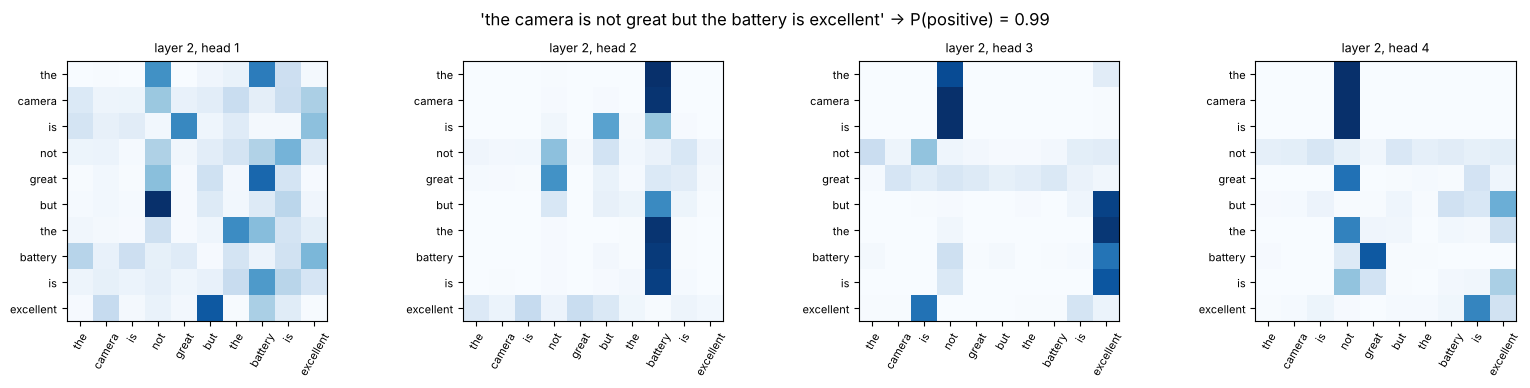

In [14]:
def show_attention(sentence, layer=0):
    toks = sentence.split(); x = torch.zeros(1, max_len, dtype=torch.long)
    x[0, :len(toks)] = torch.tensor([vocab[w] for w in toks])
    with torch.no_grad():
        logits, attns = tf_model(x, return_attn=True)
    p = torch.softmax(logits, -1)[0, 1].item()
    w = attns[layer][0, :, :len(toks), :len(toks)].numpy()               # (heads, T, T)
    fig, axes = plt.subplots(1, w.shape[0], figsize=(4 * w.shape[0], 3.8))
    for h_, ax in enumerate(axes):
        ax.imshow(w[h_], cmap="Blues"); ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=60, fontsize=8)
        ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=8); ax.set_title(f"layer {layer + 1}, head {h_ + 1}", fontsize=9); ax.grid(False)
    plt.suptitle(f"'{sentence}' → P(positive) = {p:.2f}"); plt.tight_layout(); plt.show()

show_attention("the camera is not great but the battery is excellent", layer=1)

## 8. Why transformers took over — and what they cost

| | RNN / LSTM | Transformer |
|---|---|---|
| Path between distant tokens | O(n) steps — signal fades | **1 step** — direct attention |
| Parallel over the sequence | ✗ (step by step) | ✓ (all positions at once → GPUs) |
| Compute per layer | O(n · d²) | **O(n² · d)** for attention + O(n · d²) |
| Memory for long inputs | small | the n × n attention matrix grows quadratically |
| Inductive bias | order built in | needs positional encoding; learns more from data |

The quadratic cost in sequence length n is the main limitation, and why there's a whole zoo of efficient-attention ideas: FlashAttention (same maths, memory-efficient GPU kernels), sliding-window/sparse attention, linear attention, and state-space models (Mamba) that revisit recurrence.

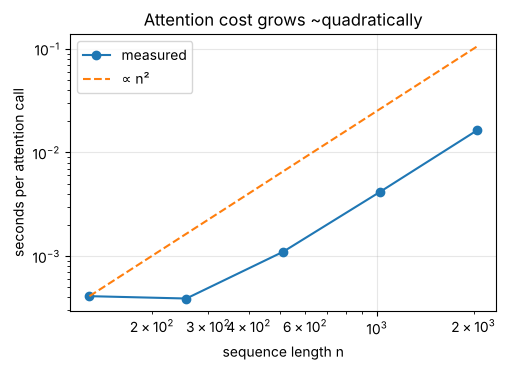

In [15]:
ns = [128, 256, 512, 1024, 2048]; times = []
for n in ns:
    q = torch.randn(1, 4, n, 64)
    t0 = time.perf_counter()
    for _ in range(5): F.scaled_dot_product_attention(q, q, q)
    times.append((time.perf_counter() - t0) / 5)
plt.loglog(ns, times, "o-", label="measured"); plt.loglog(ns, times[0] * (np.array(ns) / ns[0]) ** 2, "--", label="∝ n²")
plt.xlabel("sequence length n"); plt.ylabel("seconds per attention call"); plt.legend(); plt.title("Attention cost grows ~quadratically"); plt.show()

**Transformers beyond text:** Vision Transformers split an image into 16×16 patches and treat them as tokens; the same architecture handles audio, proteins (AlphaFold), time series, and multimodal models that mix text and images.

## Key takeaways
- Order carries meaning; bag-of-words can't read it.
- RNNs carry a hidden state through time and train with BPTT, but gradients vanish over long ranges.
- LSTMs/GRUs add gates and an additive memory path; gradients survive much longer.
- Attention = softmax(QKᵀ/√d)V: a learned, soft lookup over all positions; multi-head = several in parallel.
- Self-attention ignores order → add positional encodings. Causal masks make decoders.
- Transformer block = attention + feed-forward, each with residual + LayerNorm. Parallel and powerful, but O(n²) in length.

## Exercises
1. Remove the positional embedding from `TransformerClassifier` and retrain. Which kind of sentence (plain / negated / contrast) suffers, and why?
2. Add a **GRU** to the review comparison table.
3. Write a GRU cell from its equations (update gate z, reset gate r) and check it against `nn.GRUCell`.
4. In `gradient_through_time`, replace tanh by the identity (a *linear* RNN). How do the curves change?

In [16]:
# Exercise 1 — solution
class NoPositions(TransformerClassifier):
    def forward(self, ids, return_attn=False):
        pad = ids == 0; x = self.tok(ids)                          # ← no position information
        for blk in self.blocks: x, _ = blk(x, pad)
        return self.head(self.ln(x).masked_fill(pad[..., None], 0).sum(1) / (~pad).sum(1, keepdim=True))
torch.manual_seed(0)
nopos = NoPositions(len(vocab) + 1, max_len=max_len)
fit(nopos, ids[idx_tr], y_all[idx_tr], ids[idx_te], y_all[idx_te], epochs=12, lr=1e-3); nopos.eval()
with torch.no_grad(): print("transformer WITHOUT positions:", by_kind(nopos(ids[idx_te]).argmax(1).numpy()))
print("Negation still works (the words 'not' and 'great' co-occur regardless of order), but 'A but B' needs to know WHICH")
print("clause came after 'but' — that's pure order information.")

transformer WITHOUT positions: {'plain': 1.0, 'negated': 1.0, 'contrast': 0.778, 'overall': 0.923}
Negation still works (the words 'not' and 'great' co-occur regardless of order), but 'A but B' needs to know WHICH
clause came after 'but' — that's pure order information.


**Next:** [17 · NLP & Large Language Models](17_nlp_and_llms.ipynb) — tokenisers, embeddings, language models, and a tiny GPT trained from scratch.

*Going deeper / interview prep:* `DL_Interview_Notes.md` Part 6 (RNN, BPTT, LSTM, GRU) and Part 7 (attention, multi-head, positional encoding, the transformer block, complexity, why transformers beat RNNs) · `NLP_LLM_Interview_Notes.md` §7.5 (RoPE) · code: `dl_from_scratch.py` (LSTM and attention from scratch), `nlp_from_scratch.py`.